Evaluate regression models by calculating RMSE, MAE, and R-squared metrics, performing residual diagnostics, and validating predictive accuracy across different subpopulations and temporal splits.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 1200

In [4]:
patient_id = [f"PAT-{i:04d}" for i in range(1, n_samples + 1)]
site = np.random.choice(['Site_A_Academic', 'Site_B_Community', 'Site_C_Rural'], size=n_samples, p=[0.5, 0.3, 0.2])
admission_year = np.random.choice([2021, 2022, 2023, 2024], size=n_samples, p=[0.25, 0.25, 0.25, 0.25])

In [5]:
age = np.random.normal(58, 14, n_samples).clip(18, 90).round(1)
bmi = np.random.normal(27.5, 5.5, n_samples).clip(16.0, 48.0).round(1)
comorbidity_index = np.random.poisson(lam=2, size=n_samples).clip(0, 8)
baseline_a1c = np.random.normal(7.8, 1.4, n_samples).clip(5.5, 13.0).round(1)

In [6]:
base_los = (
    0.05 * (age - 58)
    + 0.12 * (bmi - 27.5)
    + 1.40 * comorbidity_index
    + 0.85 * (baseline_a1c - 7.8)
    + 0.08 * (age - 58) * comorbidity_index  # Interaction term
    + 3.50
)

In [7]:
noise = np.random.normal(0, 0.3 * np.abs(base_los) + 0.5)
length_of_stay = np.clip(base_los + noise, 1.0, 30.0).round(2)

In [8]:
df_reg = pd.DataFrame({
    'patient_id': patient_id,
    'site': site,
    'admission_year': admission_year,
    'age': age,
    'bmi': bmi,
    'comorbidity_index': comorbidity_index,
    'baseline_a1c': baseline_a1c,
    'length_of_stay_days': length_of_stay
})

In [9]:
print("Dataset Shape:", df_reg.shape)
print("Temporal Split Counts (Admission Year):\n", df_reg['admission_year'].value_counts().sort_index())
print("\nSubpopulation Split Counts (Clinical Site):\n", df_reg['site'].value_counts())

Dataset Shape: (1200, 8)
Temporal Split Counts (Admission Year):
 admission_year
2021    305
2022    291
2023    314
2024    290
Name: count, dtype: int64

Subpopulation Split Counts (Clinical Site):
 site
Site_A_Academic     588
Site_B_Community    359
Site_C_Rural        253
Name: count, dtype: int64


In [10]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [11]:
train_mask = df_reg['admission_year'] < 2024
test_mask = df_reg['admission_year'] == 2024

In [12]:
df_train = df_reg[train_mask].copy()
df_test = df_reg[test_mask].copy()

In [13]:
feature_cols = ['age', 'bmi', 'comorbidity_index', 'baseline_a1c', 'site']
target_col = 'length_of_stay_days'

In [14]:
X_train, y_train = df_train[feature_cols], df_train[target_col]
X_test, y_test = df_test[feature_cols], df_test[target_col]

In [15]:
numeric_features = ['age', 'bmi', 'comorbidity_index', 'baseline_a1c']
categorical_features = ['site']

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ]
)

In [17]:
reg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, random_state=42))
])

In [18]:
reg_pipeline.fit(X_train, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi',
                                                   'comorbidity_index',
                                                   'baseline_a1c']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['site'])])),
                ('model',
                 HistGradientBoostingRegressor(learning_rate=0.05, max_iter=150,
                                               random_state=42))])

In [19]:
y_pred = reg_pipeline.predict(X_test)
df_test['pred_length_of_stay'] = y_pred
df_test['residual'] = y_test - y_pred

In [20]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [21]:
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f} days")
print(f"Mean Absolute Error (MAE)      : {mae:.4f} days")
print(f"R-squared Coefficient (R²)     : {r2:.4f}")

Root Mean Squared Error (RMSE) : 2.7586 days
Mean Absolute Error (MAE)      : 1.9529 days
R-squared Coefficient (R²)     : 0.6373


In [22]:
import matplotlib.pyplot as plt
import scipy.stats as stats

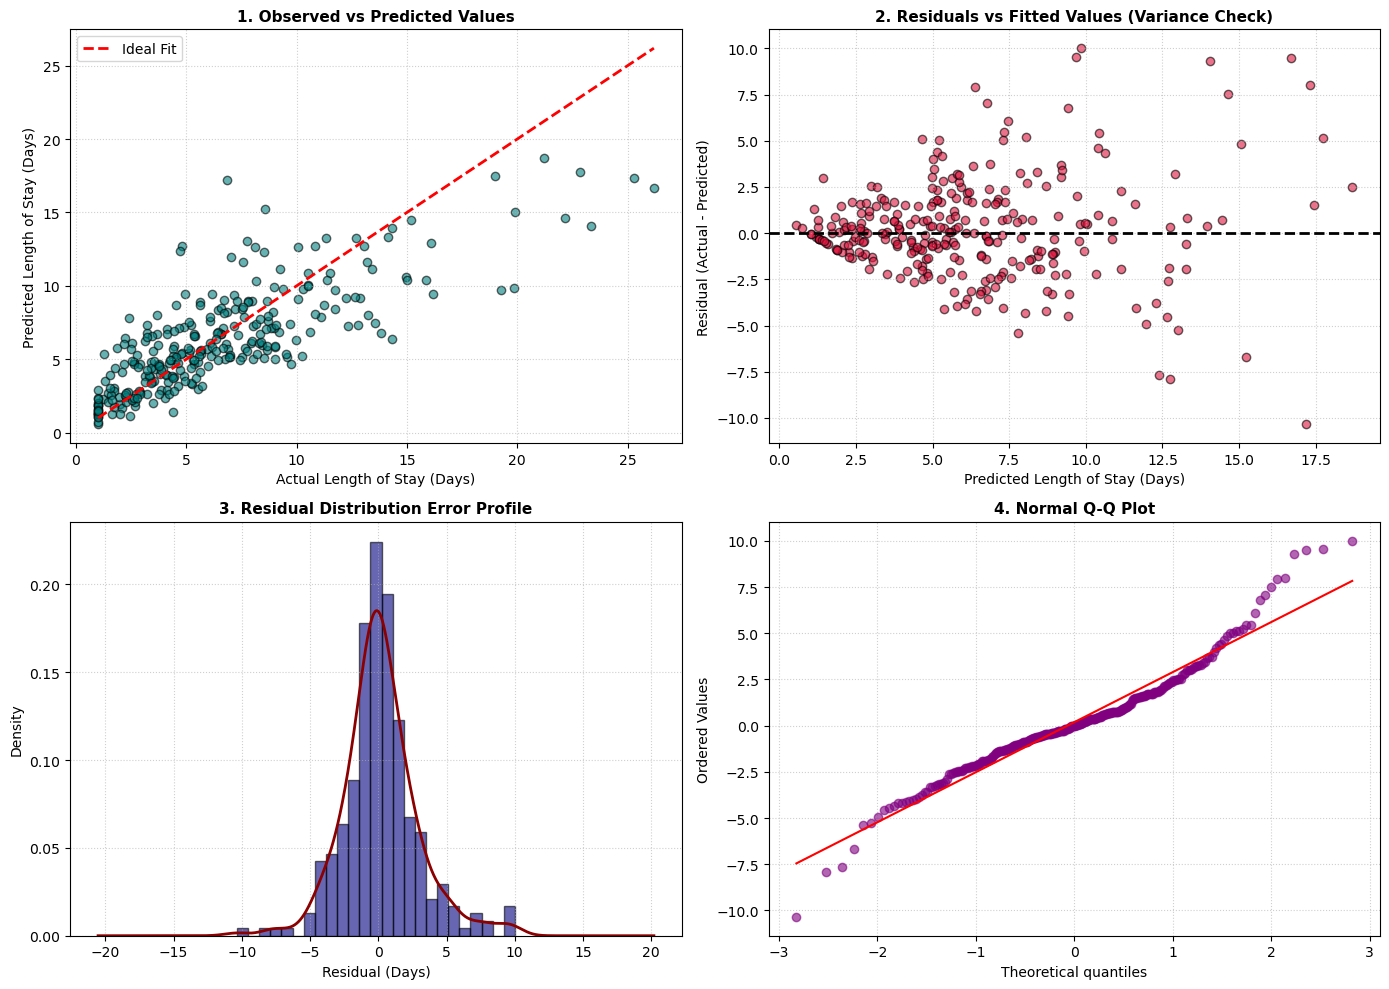

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(y_test, y_pred, alpha=0.6, color='teal', edgecolor='k')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[0, 0].set_title("1. Observed vs Predicted Values", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Actual Length of Stay (Days)")
axes[0, 0].set_ylabel("Predicted Length of Stay (Days)")
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend()

axes[0, 1].scatter(y_pred, df_test['residual'], alpha=0.6, color='crimson', edgecolor='k')
axes[0, 1].axhline(0, color='black', linestyle='--', lw=2)
axes[0, 1].set_title("2. Residuals vs Fitted Values (Variance Check)", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Predicted Length of Stay (Days)")
axes[0, 1].set_ylabel("Residual (Actual - Predicted)")
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

axes[1, 0].hist(df_test['residual'], bins=25, density=True, color='navy', alpha=0.6, edgecolor='black')
df_test['residual'].plot(kind='kde', ax=axes[1, 0], color='darkred', lw=2)
axes[1, 0].set_title("3. Residual Distribution Error Profile", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Residual (Days)")
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

stats.probplot(df_test['residual'], dist="norm", plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_color('purple')
axes[1, 1].get_lines()[0].set_alpha(0.6)
axes[1, 1].set_title("4. Normal Q-Q Plot", fontsize=11, fontweight='bold')
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [25]:
def compute_subgroup_metrics(df, group_col):
    results = []
    for group_name, group_data in df.groupby(group_col):
        y_true_g = group_data[target_col]
        y_pred_g = group_data['pred_length_of_stay']
        
        rmse_g = np.sqrt(mean_squared_error(y_true_g, y_pred_g))
        mae_g = mean_absolute_error(y_true_g, y_pred_g)
        r2_g = r2_score(y_true_g, y_pred_g)
        
        results.append({
            group_col.capitalize(): group_name,
            'Sample Count': len(group_data),
            'RMSE': round(rmse_g, 4),
            'MAE': round(mae_g, 4),
            'R²': round(r2_g, 4)
        })
    return pd.DataFrame(results).set_index(group_col.capitalize())

In [26]:
df_site_metrics = compute_subgroup_metrics(df_test, 'site')
print("--- Subpopulation Accuracy (Out-of-Time Test Set by Site) ---")
print(df_site_metrics)

--- Subpopulation Accuracy (Out-of-Time Test Set by Site) ---
                  Sample Count    RMSE     MAE      R²
Site                                                  
Site_A_Academic            148  2.6162  1.8907  0.5873
Site_B_Community            80  3.1913  2.1964  0.6559
Site_C_Rural                62  2.4727  1.7873  0.6740


In [27]:
df_all_pred = df_reg.copy()
df_all_pred['pred_length_of_stay'] = reg_pipeline.predict(df_all_pred[feature_cols])
df_yearly_metrics = compute_subgroup_metrics(df_all_pred, 'admission_year')

In [28]:
print(df_yearly_metrics)

                Sample Count    RMSE     MAE      R²
Admission_year                                      
2021                     305  1.6177  1.1833  0.8681
2022                     291  1.5881  1.1554  0.8702
2023                     314  1.6727  1.1842  0.8661
2024                     290  2.7586  1.9529  0.6373


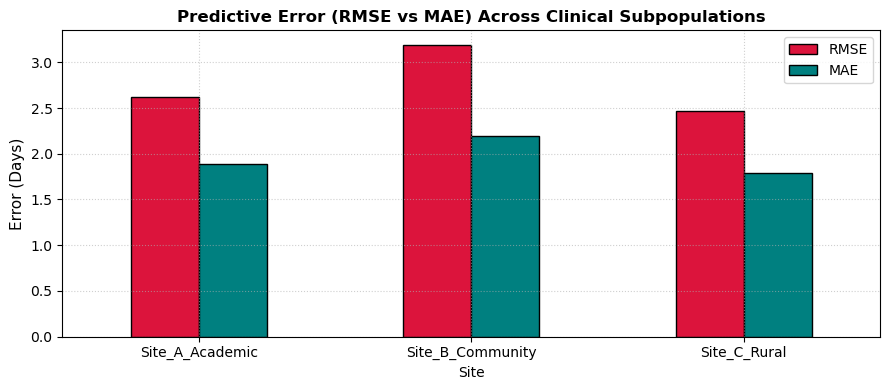

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
df_site_metrics[['RMSE', 'MAE']].plot(kind='bar', ax=ax, color=['crimson', 'teal'], edgecolor='black')
ax.set_title("Predictive Error (RMSE vs MAE) Across Clinical Subpopulations", fontsize=12, fontweight='bold')
ax.set_ylabel("Error (Days)", fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()